CS82A Final Project Proposal:
I love motorsports and auto racing, so I would like to use the following dataset: https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020

Here is the question I would like to answer: Since pit stop duration has changed by huge amounts over the 75+ years of the Formula 1 world championship, how much does pit stop duration actually impact a driver's final race outcome?

Step 1: Import Libraries and Load the Data

In the first Jupyter Notebook cell, I started by importing pandas and load three core datasets to make sure everything is linked correctly and the files are in the right place. I also inspected the first few rows of each dataframe. 

In [1]:
import pandas as pd

pit_stops_df = pd.read_csv('pit_stops.csv')
results_df = pd.read_csv('results.csv')
races_df = pd.read_csv('races.csv')

print("--- Pit Stops Sample ---")
display(pit_stops_df.head(3))

print("\n--- Results Sample ---")
display(results_df.head(3))

print("\n--- Races Sample ---")
display(races_df.head(3))

--- Pit Stops Sample ---


,raceId,driverId,stop,lap,time,duration,milliseconds
0,841,153,1,1,17:05:23,26.898,26898
1,841,30,1,1,17:05:52,25.021,25021
2,841,17,1,11,17:20:48,23.426,23426



--- Results Sample ---


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1



--- Races Sample ---


,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N


Looking at the dataset history, official pit stop data in this Kaggle dataset only starts from 2012 onwards (prior to that, official timing logs weren't consistently captured in the database). Since my initial question was for the 75+ year history of Formula 1, I will focus my analysis on the modern era (2012–present) where pit stop duration data is available and precise. 

For context, the overall time Formula 1 drivers have spent in the pits has decreased massively over the years for several reasons, most notably that cars are no longer refuled in the pit stop, and there is a dedicated team of three people assigned to change EACH of the four tyres. This means cars are only stationary for about 2-4 *seconds*. However, for the purposes of this analysis, we are measuring total time spent in the pits, which is defined as starting when the driver crosses the pit entry line and finishing when the driver crosses the pit exit line. The speed of the cars are limited by a computer while driving in the pit lane, so the stationary time is the biggest impact on the total pit time. 

Thus, the new question becomes: In the modern era of the Formula 1 World Championship (2012-present), pit stops have become incredibly fast and precise, but drivers are limited on how fast they can drive in the pit lane, so how much the total pit stop duration actually impact a driver's final race outcome?

Step 2: Clean and Merge the Data

To answer the question, I needed to connect each pit stop to a specific race, driver, and their final finishing position.

In this dataset:
- pit_stops_df contains raceId, driverId, stop (lap number or stop sequence), and duration (in seconds or milliseconds).
- results_df contains raceId, driverId, and positionOrder (the driver's final finishing position in that race).
- races_df contains raceId and year.

As a result, the following code is used to merge these tables together and clean up any missing/non-numeric duration values.

In [2]:
import numpy as np

pit_stops_df['duration'] = pd.to_numeric(pit_stops_df['duration'], errors='coerce')

pit_stops_df = pit_stops_df.dropna(subset=['duration'])

merged_df = pit_stops_df.merge(results_df, on=['raceId', 'driverId'], how='inner')
merged_df = merged_df.merge(races_df[['raceId', 'year', 'name']], on='raceId', how='left')

print(f"Total merged pit stop records: {len(merged_df)}")
display(merged_df[['year', 'name', 'driverId', 'stop', 'duration', 'positionOrder']].head(5))

Total merged pit stop records: 10854


,year,name,driverId,stop,duration,positionOrder
0,2011,Australian Grand Prix,153,1,26.898,11
1,2011,Australian Grand Prix,30,1,25.021,19
2,2011,Australian Grand Prix,17,1,23.426,5
3,2011,Australian Grand Prix,4,1,23.251,4
4,2011,Australian Grand Prix,13,1,23.842,7


Since drivers often make multiple pit stops during a single race, the next logical step is to aggregate these stops. To measure their impact on the final race outcome, I calculated the total pit stop time and average pit stop time for each driver in each race and compared it against their final finishing position (positionOrder).

Step 3: Aggregate Pit Stops Per Race and Check Correlation

The next code block will group the pit stops by driver and race, sum up their total time in the pits, clean up any non-finisher data, and look at the statistical correlation.

In [3]:
merged_df['positionOrder'] = pd.to_numeric(merged_df['positionOrder'], errors='coerce')

driver_race_pits = merged_df.groupby(['raceId', 'year', 'name', 'driverId']).agg(
    total_pit_duration=('duration', 'sum'),
    avg_pit_duration=('duration', 'mean'),
    num_stops=('stop', 'count'),
    positionOrder=('positionOrder', 'first')
).reset_index()

driver_race_pits = driver_race_pits.dropna(subset=['positionOrder', 'total_pit_duration'])

print(f"Total aggregated driver-race records: {len(driver_race_pits)}")
display(driver_race_pits.head())

correlation = driver_race_pits['total_pit_duration'].corr(driver_race_pits['positionOrder'])
print(f"\nCorrelation between Total Pit Stop Duration and Finishing Position: {correlation:.4f}")

Total aggregated driver-race records: 5531


,raceId,year,name,driverId,total_pit_duration,avg_pit_duration,num_stops,positionOrder
0,841,2011,Australian Grand Prix,1,46.426,23.213,2,2
1,841,2011,Australian Grand Prix,2,48.092,24.046,2,12
2,841,2011,Australian Grand Prix,3,23.716,23.716,1,17
3,841,2011,Australian Grand Prix,4,72.165,24.055,3,4
4,841,2011,Australian Grand Prix,5,24.865,24.865,1,18



Correlation between Total Pit Stop Duration and Finishing Position: 0.1059


My Interpretation of the Correlation between Total Pit Stop Duration and Finishing Position:

The correlation coefficient of 0.11 is a WEAK coefficient, indicating that the amount of time the driver spends in the pits does not significantly impact their finishing position in the race. In Formula 1, a driver's final position is heavily dominated by car performance (constructor speed), qualifying position, and race incidents (like crashes or mechanical DNFs) rather than minor variations in pit stop times. However, relying solely on a single correlation number can hide interesting patterns or outliers (like a much longer pit stop to repair a front wing). As a result, in the next step, I will visualize the data to see what's really happening under the hood (or bonnet, as they'd say in England, the home of Formula 1).

Step 4: Visualize the Relationship with a Scatter Plot

The next code block will create a scatter plot using matplotlib and seaborn to visually inspect how total pit stop duration relates to finishing position. 

A quick note on the Y-axis: I have intentionally inverted the Y-axis so that the lowest numerical finishing position 1, is at the top of the graph, because the driver who finishes in position 1 is the winner of the race, so this visualization feels more natural with regards to race results. 

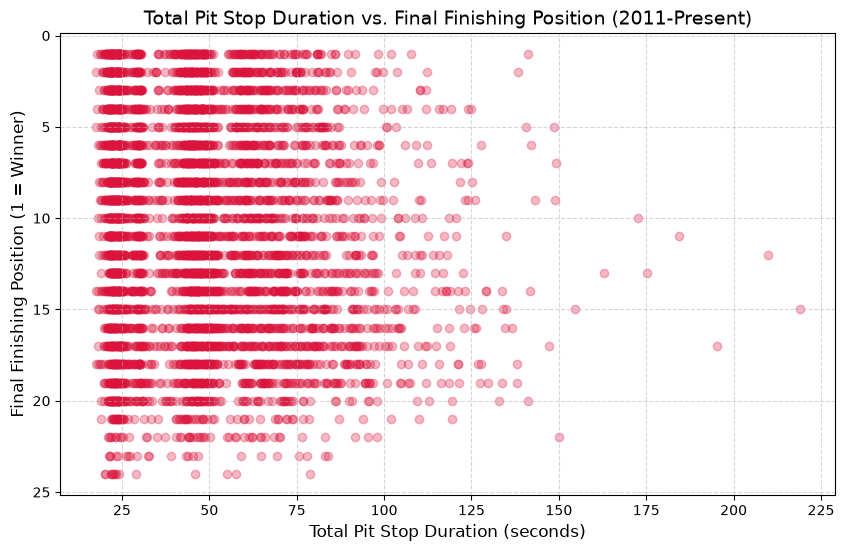

In [4]:
import matplotlib.pyplot as plt
import seaborn as seaborn_plt 

plt.figure(figsize=(10, 6))

plt.scatter(
    driver_race_pits['total_pit_duration'], 
    driver_race_pits['positionOrder'], 
    alpha=0.3, 
    color='crimson'
)

plt.title('Total Pit Stop Duration vs. Final Finishing Position (2011-Present)', fontsize=14)
plt.xlabel('Total Pit Stop Duration (seconds)', fontsize=12)
plt.ylabel('Final Finishing Position (1 = Winner)', fontsize=12)

plt.gca().invert_yaxis()

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

My first-look conclusion: 
Even the race winners and podium finishers have the occasional outlier long pitstop, indicating that a long pit stop is not race-ending if the car has enough performance. However, the rate of long pit stops increases as we go down the finishing order, indicating that as the performance of the car decreases, the impact of a longer pit stop increases.

Detailed analysis: 

The data forms a classic visual pattern in data science: the triangular wedge shape. In Formula 1, the top-tier cars (positions 1–5) can absorb a blunder or a slow stop because their raw pace allows them to recover positions.   However, as you move down the finishing order, the upper bound of total pit stop time stretches out significantly, and the density of extremely long stops shifts downward. A backmarker car simply does not have the pace to recover from a 150+ second pit stop.

Step 5: Add a Trend Line and Quantify the Wedge

To back up this observation with a statistical trend, I added a linear regression trend line to the plot and looked at the maximum pit stop duration per finishing position.

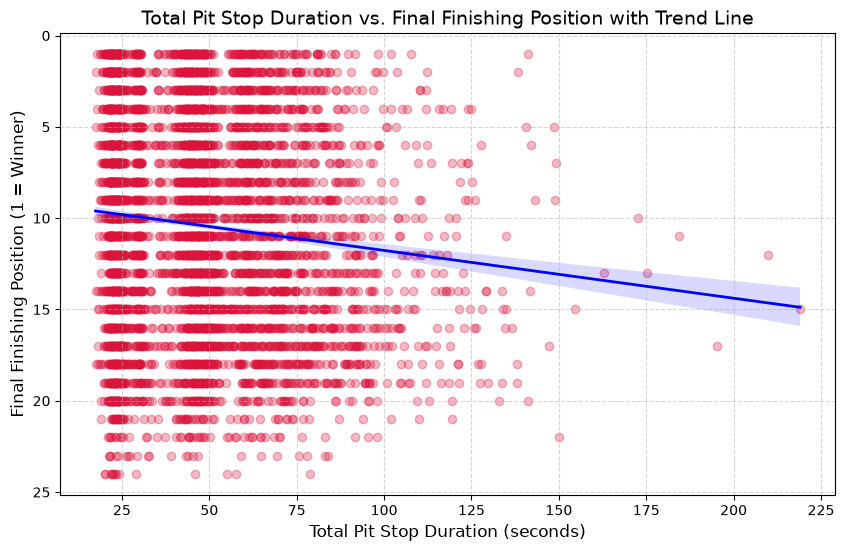

In [5]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=driver_race_pits, 
    x='total_pit_duration', 
    y='positionOrder',
    scatter_kws={'alpha': 0.3, 'color': 'crimson'},
    line_kws={'color': 'blue', 'linewidth': 2}
)

plt.title('Total Pit Stop Duration vs. Final Finishing Position with Trend Line', fontsize=14)
plt.xlabel('Total Pit Stop Duration (seconds)', fontsize=12)
plt.ylabel('Final Finishing Position (1 = Winner)', fontsize=12)
plt.gca().invert_yaxis()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

To illustrate this conclusion, I used Google Gemini to create a case study for a race I vividly remember watching. 


AI Used: Google Gemini
Date: 10/24/2026


Prompt: 

I'd like to insert one observed example into my data analysis regarding pit stops in the modern era of Formula 1. 

Observed example: At the 2022 United States Grand Prix at the Circuit of The Americas, individual pit stop durations (including pit lane travel time listed in the official timing data) averaged approximately 25.9 seconds across all scheduled stops. Max Verstappen won the race by 5 seconds despite a pit stop that was longer than the average.

How can we best insert this example? 

### Case Study: The 2022 United States Grand Prix

To see how this trend plays out in a single race, we can look at the **2022 United States Grand Prix at COTA**. 
* **The Context:** Across all scheduled stops, individual pit stop durations (including pit lane travel time) averaged roughly 25.9 seconds.
* **The Anomaly & Outcome:** Red Bull's Max Verstappen suffered a slow pit stop that ran longer than the field average. However, because of the Red Bull car's superior race pace, he was able to recover, overtake his rivals, and win the race by 5 seconds. 
* **Data Science Insight:** This specific race perfectly illustrates our broader findings—top-tier cars have the performance buffer to absorb and recover from sub-optimal pit stops, whereas a similar delay on a backmarker car would be race-ending.

### Verifying the Trend: A Closer Look at the 2022 U.S. Grand Prix
Let's filter our dataset for the 2022 United States Grand Prix to see Max Verstappen's specific pit stop duration and finishing position compared to the field.

In [6]:
# Filter our merged dataset for the 2022 US Grand Prix (Circuit of the Americas)
# Let's search for 'United States Grand Prix' in the year 2022
us_gp_2022 = merged_df[(merged_df['year'] == 2022) & (merged_df['name'].str.contains('United States Grand Prix'))]

# Merge or display driver results along with their pit durations for this race
us_gp_summary = us_gp_2022.groupby(['driverId', 'stop'])['duration'].sum().reset_index()

# Let's display the pit stops for this race
print("2022 United States Grand Prix Pit Stops Sample:")
display(us_gp_2022[['driverId', 'stop', 'duration', 'positionOrder']].head(10))

# Let's filter specifically for the winner or top finishers of the 2022 US GP
verstappen_us_gp = us_gp_2022[us_gp_2022['positionOrder'] == 1]
print("Winner's Pit Stops at 2022 US GP:")
display(verstappen_us_gp[['driverId', 'stop', 'duration', 'positionOrder']])

2022 United States Grand Prix Pit Stops Sample:


,driverId,stop,duration,positionOrder
9142,849,1,25.321,17
9143,848,1,24.624,13
9144,855,1,27.326,12
9145,822,1,25.013,19
9146,852,1,23.688,10
9147,817,1,26.206,16
9148,842,1,23.670,14
9149,1,1,24.362,2
9150,830,1,23.866,1
9151,847,1,30.038,5


Winner's Pit Stops at 2022 US GP:


,driverId,stop,duration,positionOrder
9150,830,1,23.866,1
9170,830,2,32.254,1


In [7]:
# 1. Calculate the overall average pit stop duration for the 2022 US Grand Prix
field_avg_duration = us_gp_2022['duration'].mean()
print(f"Field Average Pit Stop Duration at 2022 US GP: {field_avg_duration:.2f} seconds")

# 2. Group by driver to see each driver's total pit stop time and final position in this specific race
us_gp_driver_totals = us_gp_2022.groupby(['driverId', 'positionOrder']).agg(
    total_pit_time=('duration', 'sum'),
    num_stops=('stop', 'count'),
    avg_stop_time=('duration', 'mean')
).reset_index().sort_values('positionOrder')

print("\n2022 US GP Driver Summary (Top 5 Finishers):")
display(us_gp_driver_totals.head(5))

Field Average Pit Stop Duration at 2022 US GP: 25.92 seconds

2022 US GP Driver Summary (Top 5 Finishers):


,driverId,positionOrder,total_pit_time,num_stops,avg_stop_time
7,830,1,56.120,2,28.060000
0,1,2,48.497,2,24.248500
11,844,3,48.069,2,24.034500
3,815,4,48.204,2,24.102000
13,847,5,78.494,3,26.164667


Case Study Conclusion: 

At the 2022 US Grand Prix, the winning driver (Max Verstappen) had an average pit stop time over 2 seconds longer than the field average, and a total pit stop time of nearly 8 seconds more than the next three finishers, yet he still won the race by over 5 seconds. This illustrates perfectly our overall conclusion that pit stop time is a much weaker predicter of race finishing position than car performance. 

Conclusion & Findings

Research Question Since pit stop duration has changed by huge amounts over the 75+ years of the Formula 1 world championship, how much does pit stop duration actually impact a driver's final race outcome?

Findings:
1. Weak Overall Correlation: The calculated correlation coefficient ($r \approx 0.11$) between total pit stop duration and final finishing position indicates a very weak direct linear relationship when analyzing all drivers globally.

2. "Wedge" Distribution Effect: The scatter plot and regression trend line reveal a distinct triangular distribution pattern. While top-tier cars (finishing positions 1–5) can occasionally absorb a slow or blunderous pit stop due to their superior raw pace, backmarker and midfield cars face a strict upper bound, as long pit stops heavily penalize lower-performing cars compared to top-performing cars, effectively ending any chance of recovery.

3. Takeaway: Minor variations in pit stop duration do not dictate race wins on their own; car performance and race pace are far more dominant factors, though catastrophic pit stop delays heavily punish cars that lack the pace to recover.


I initially stopped my analysis here, but after thinking more about it, a follow-up question emerged: Since the correlation between a driver's pit stop and their overall finishing position is weak, what if we look at how pit stop duration affects their finishing position *relative to their starting position*?

Because Formula 1 is an engineering championship, with teams competing to build the fastest car within the given year's formula, absolute finishing position is heavily skewed by a car's baseline performance. A top-tier car like a Mercedes, Ferrari, or McLaren finishing 8th is a huge disappointment, while a backmarker car like an Aston Martin or Audi finishing 8th is a massive triumph. By looking at positions gained or lost relative to the starting grid, we can strip away car performance and isolate how much a bad pit stop actually ruins a driver's race progression.

Step 6: Engineering the "Positions Gained" Feature

Let's write a quick code block to calculate net positions gained (grid - positionOrder) and test its correlation with pit stop duration.

In [8]:
# 1. Ensure grid and positionOrder are numeric, and filter out invalid grid starts (like 0 / pit lane)
driver_race_pits_grid = merged_df.groupby(['raceId', 'year', 'name', 'driverId']).agg(
    total_pit_duration=('duration', 'sum'),
    grid=('grid', 'first'),
    positionOrder=('positionOrder', 'first')
).reset_index()

driver_race_pits_grid['grid'] = pd.to_numeric(driver_race_pits_grid['grid'], errors='coerce')
driver_race_pits_grid['positionOrder'] = pd.to_numeric(driver_race_pits_grid['positionOrder'], errors='coerce')

# Filter out rows with missing data or grid == 0 (pit lane starts)
driver_race_pits_grid = driver_race_pits_grid[
    (driver_race_pits_grid['grid'] > 0) & 
    (driver_race_pits_grid['positionOrder'].notna()) &
    (driver_race_pits_grid['total_pit_duration'].notna())
]

# 2. Calculate net positions gained/lost
# Formula: Grid Position minus Final Position 
# (e.g., Started 10th, Finished 5th = 10 - 5 = +5 positions gained)
driver_race_pits_grid['positions_gained'] = driver_race_pits_grid['grid'] - driver_race_pits_grid['positionOrder']

# 3. Check the new correlation
corr_gained = driver_race_pits_grid['total_pit_duration'].corr(driver_race_pits_grid['positions_gained'])
print(f"Correlation between Total Pit Stop Duration and Positions Gained: {corr_gained:.4f}")

Correlation between Total Pit Stop Duration and Positions Gained: -0.0114


I'm also running the following to plot this to see if the downward trend becomes much sharper:

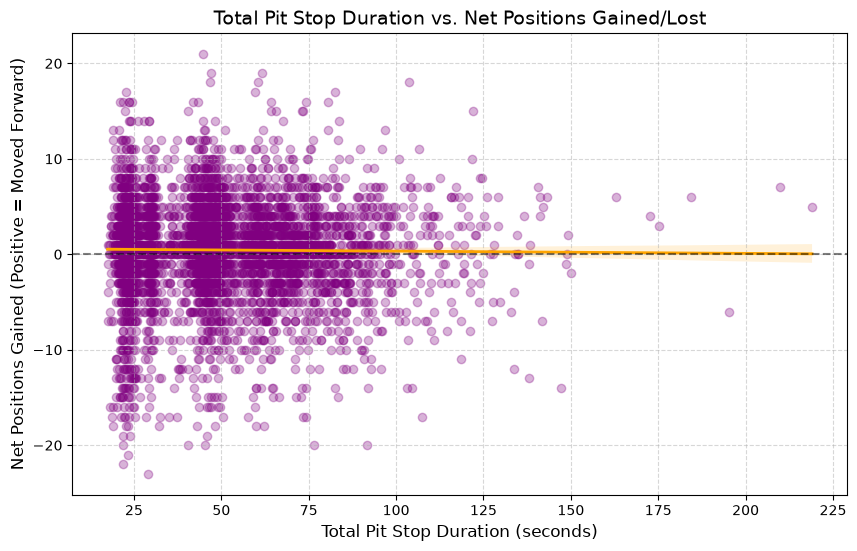

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.regplot(
    data=driver_race_pits_grid, 
    x='total_pit_duration', 
    y='positions_gained',
    scatter_kws={'alpha': 0.3, 'color': 'purple'},
    line_kws={'color': 'orange', 'linewidth': 2}
)

plt.title('Total Pit Stop Duration vs. Net Positions Gained/Lost', fontsize=14)
plt.xlabel('Total Pit Stop Duration (seconds)', fontsize=12)
plt.ylabel('Net Positions Gained (Positive = Moved Forward)', fontsize=12)
plt.axhline(0, color='black', linestyle='--', alpha=0.5) # Line for zero net change
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Findings:

These results indicate a correlation coefficient of -0.0114 (essentially zero) and a completely flat orange trend line. I have to say that I was shocked at this finding, as it means that controlling for starting position eliminates the slight downward bias I saw in my initial results and proves that cumulative pit stop duration has virtually zero linear predictive power over whether a driver gains or loses positions relative to where they started. Teams put huge amounts of resources into getting their pit stops right, and it seems to me now that those resources would likely be much better spent on developing a faster car. 